# Practical 23: Support Vector Regression (SVR)

**Aim:** To predict employee salary based on position level using Support Vector Regression with a linear kernel.

**Dataset:** Position Salaries (Kaggle)

**Kaggle link:** https://www.kaggle.com/datasets/akram24/position-salaries

### Dataset setup
1. Download the dataset from Kaggle.
2. Extract the ZIP file.
3. Keep `Position_Salaries.csv` in the same folder as this notebook.
4. Run the cells one by one using Shift + Enter.

This notebook follows your uploaded `exp3.ipynb` style: load data, display it, select X and y, train the model, predict salary, display the score, and plot the regression curve.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

## 2. Load the dataset

In [2]:
df = pd.read_csv("Position_Salaries.csv")
df.head()

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


## 3. Display the dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Position  10 non-null     object
 1   Level     10 non-null     int64 
 2   Salary    10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 368.0+ bytes


In [4]:
df.describe()

,Level,Salary
count,10.00000,10.000000
mean,5.50000,249500.000000
std,3.02765,299373.883668
min,1.00000,45000.000000
25%,3.25000,65000.000000
50%,5.50000,130000.000000
75%,7.75000,275000.000000
max,10.00000,1000000.000000


## 4. Select independent and dependent variables

In [5]:
X = df[["Level"]]
y = df["Salary"]

## 5. Apply feature scaling

In [6]:
sc_X = StandardScaler()
sc_y = StandardScaler()

X_scaled = sc_X.fit_transform(X)
y_scaled = sc_y.fit_transform(y.values.reshape(-1, 1)).ravel()

## 6. Display the data

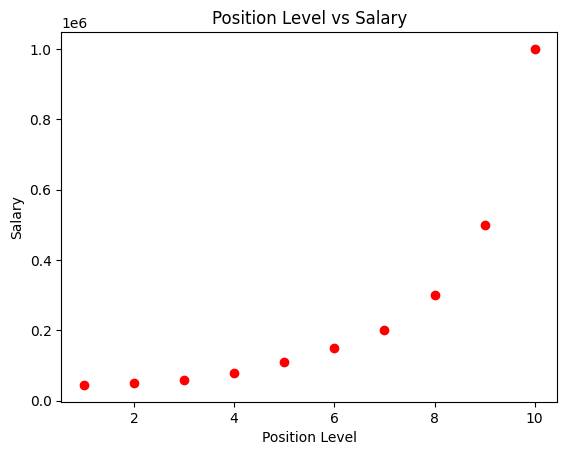

In [7]:
plt.scatter(X, y, color="red")
plt.title("Position Level vs Salary")
plt.xlabel("Position Level")
plt.ylabel("Salary")
plt.show()

## 7. Create and train SVR model using linear kernel

In [8]:
model = SVR(kernel="linear")
model.fit(X_scaled, y_scaled)

SVR(kernel='linear')

## 8. Predict salary

In [9]:
ip = sc_X.transform([[6.5]])
predicted_salary = sc_y.inverse_transform(model.predict(ip).reshape(-1, 1))
print("Predicted Salary:", predicted_salary[0][0])

Predicted Salary: 216903.8337115843


/Users/aryanchavan24/.venvs/jupyter/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 9. Display model accuracy

In [10]:
print("R2 Score:", model.score(X_scaled, y_scaled))

R2 Score: 0.45378133514512575


## 10. Display the regression curve

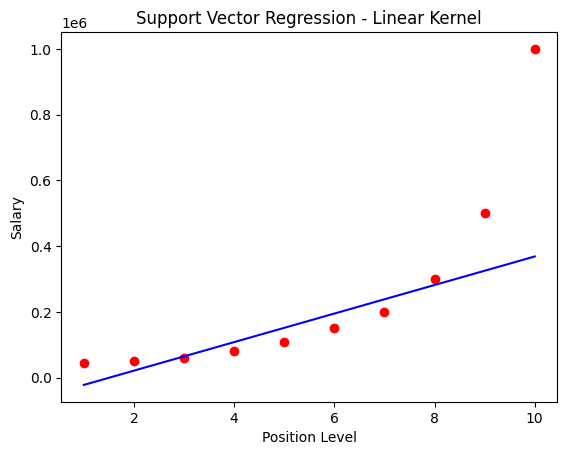

In [11]:
plt.scatter(X, y, color="red")
plt.plot(X, sc_y.inverse_transform(model.predict(X_scaled).reshape(-1, 1)),
         color="blue")
plt.title("Support Vector Regression - Linear Kernel")
plt.xlabel("Position Level")
plt.ylabel("Salary")
plt.show()

## Conclusion

Thus, Support Vector Regression with a linear kernel was implemented to predict employee salary based on position level. The model was trained using `fit()` and salary was predicted using `predict()`. The graph shows the actual salary values and the SVR predictions.

## Quick revision

| Code | Purpose |
|---|---|
| `pd.read_csv()` | Load Kaggle dataset |
| `SVR(kernel="linear")` | Create linear SVR model |
| `StandardScaler()` | Scale input and output values |
| `model.fit()` | Train the model |
| `model.predict()` | Predict salary |
| `model.score()` | Display R² score |
| `plt.scatter()` | Display actual data points |
| `plt.plot()` | Display predicted regression curve |